In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

# 1. Load and prepare the dataset (Weeks 1-2).
df = pd.read_csv("_cancer_dataset_uae.csv")


In [5]:

# 1. Load and prepare the dataset (Weeks 1-2).
df = pd.read_csv("_cancer_dataset_uae.csv")
df["Diagnosis_Date"] = pd.to_datetime(df["Diagnosis_Date"], errors="coerce")
df["Treatment_Start_Date"] = pd.to_datetime(df["Treatment_Start_Date"], errors="coerce")
df["Treatment_Delay_Days"] = (
    df["Treatment_Start_Date"] - df["Diagnosis_Date"]
).dt.days
field = "Treatment_Delay_Days"  # Dependent variable
predictor = "Age"              # Independent variable for correlation

print("Original rows:", len(df))
print("Missing treatment delays:", df[field].isna().sum())
print("Negative treatment delays:", (df[field] < 0).sum())
# Exclude invalid or missing treatment delay for the analysis.
df = df.dropna(subset=[field]).loc[lambda x: x[field] >= 0].copy()
print("Rows included in analysis:", len(df))

# 2. Reusable descriptive-statistics function (Week 3).
# Input: a sample/DataFrame and the name of a numerical column.
def descriptive_statistics(sample, field):
    values = pd.to_numeric(sample[field], errors="coerce").dropna()
    if values.empty:
        raise ValueError("No valid numerical observations for " + field)
    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)
    return {
        "count": int(values.count()),
        "mean": values.mean(),
        "median": values.median(),
        "mode": values.mode().iloc[0],
        "minimum": values.min(),
        "maximum": values.max(),
        "range": values.max() - values.min(),
        "variance": values.var(),
        "standard_deviation": values.std(),
        "Q1": q1,
        "Q3": q3,
        "IQR": q3 - q1,
        "skewness": values.skew(),
    }


def show_statistics(title, sample, field):
    print("\n" + title)
    for label, value in descriptive_statistics(sample, field).items():
        print(f"{label}: {value:.3f}" if isinstance(value, (float, np.floating))
              else f"{label}: {value}")


# 3. Descriptive report for all patients.
show_statistics("FULL DATASET", df, field)

# 4. Simple random sampling: exactly 150 rows, without replacement (Week 2).
random_sample = df.sample(n=150, replace=False, random_state=42)
show_statistics("RANDOM SAMPLE (n=150)", random_sample, field)

# 5. Systematic sampling: random starting position, then every k-th row.
# For 10,000 rows, k = 10000 // 150 = 66.
k = len(df) // 150
rng = np.random.default_rng(42)
start = int(rng.integers(0, k))
systematic_sample = df.iloc[start::k].head(150)
print(f"\nSystematic sampling: interval = {k}, start index = {start}")
show_statistics("SYSTEMATIC SAMPLE (n=150)", systematic_sample, field)


Original rows: 10000
Missing treatment delays: 0
Negative treatment delays: 0
Rows included in analysis: 10000

FULL DATASET
count: 10000
mean: 89.347
median: 90.000
mode: 126
minimum: 0
maximum: 179
range: 179
variance: 2735.240
standard_deviation: 52.300
Q1: 44.000
Q3: 135.000
IQR: 91.000
skewness: -0.010

RANDOM SAMPLE (n=150)
count: 150
mean: 88.493
median: 88.500
mode: 1
minimum: 1
maximum: 179
range: 178
variance: 2697.325
standard_deviation: 51.936
Q1: 45.000
Q3: 131.000
IQR: 86.000
skewness: -0.025

Systematic sampling: interval = 66, start index = 5

SYSTEMATIC SAMPLE (n=150)
count: 150
mean: 87.687
median: 87.500
mode: 156
minimum: 0
maximum: 178
range: 178
variance: 2723.344
standard_deviation: 52.186
Q1: 40.500
Q3: 132.000
IQR: 91.500
skewness: 0.073


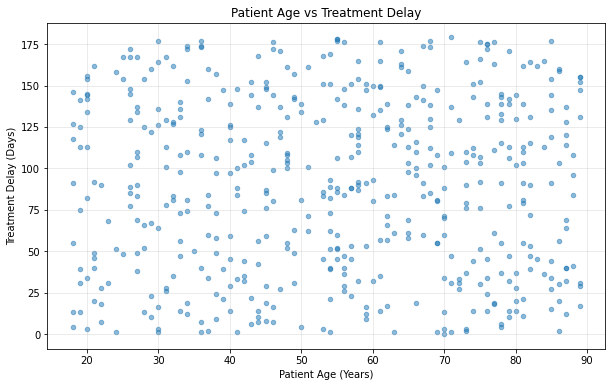

In [6]:
# Scatter Plot - Patient Age vs Treatment Delay

# Select 500 random patients
scatter_sample = df.sample(n=500, random_state=42)

plt.figure(figsize=(10, 6))

plt.scatter(
    scatter_sample['Age'],
    scatter_sample['Treatment_Delay_Days'],
    alpha=0.5,
    s=20
)

plt.title('Patient Age vs Treatment Delay')
plt.xlabel('Patient Age (Years)')
plt.ylabel('Treatment Delay (Days)')
plt.grid(True, alpha=0.3)
plt.show()

In [ ]:
plt.figure(figsize=(8, 5))

for diagnosis, color in [("B", "steelblue"), ("M", "coral")]:
    group = data[data["diagnosis"] == diagnosis]
    plt.scatter(
        group["radius_mean"],
        group["texture_mean"],
        color=color,
        alpha=0.6,
        label="Benign" if diagnosis == "B" else "Malignant"
    )

plt.xlabel("Mean radius")
plt.ylabel("Mean texture")
plt.title("Scatter: mean radius vs mean texture, grouped by diagnosis")
plt.legend(title="Diagnosis")
plt.tight_layout()
plt.show()

In [ ]:
benign = data[data["diagnosis"] == "B"]["radius_mean"]
malignant = data[data["diagnosis"] == "M"]["radius_mean"]

plt.figure(figsize=(8, 5))

plt.boxplot(
    [benign, malignant],
    labels=["Benign (B)", "Malignant (M)"]
)

plt.ylabel("Mean radius")
plt.title("Box plot: mean radius by diagnosis")
plt.tight_layout()
plt.show()

In [ ]:
plt.figure(figsize=(8, 5))

plt.hist(
    data["diagnosis_numeric"],
    bins=[-0.5, 0.5, 1.5],
    edgecolor="white"
)

plt.xticks([0, 1], ["Benign (B=0)", "Malignant (M=1)"])
plt.xlabel("Diagnosis")
plt.ylabel("Number of cases")
plt.title("Histogram of diagnosis (binary encoded outcome)")
plt.tight_layout()
plt.show()

In [ ]:
columns = [
    "diagnosis_numeric",
    "radius_mean",
    "texture_mean",
    "perimeter_mean",
    "area_mean"
]

correlation_matrix = data[columns].corr()

plt.figure(figsize=(8, 6))

plt.imshow(
    correlation_matrix,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

plt.xticks(
    range(len(columns)),
    columns,
    rotation=45,
    ha="right"
)

plt.yticks(range(len(columns)), columns)

plt.colorbar(label="Pearson correlation")
plt.title("Heat map including encoded diagnosis")
plt.tight_layout()
plt.show()

In [ ]:
# Create three radius groups
data["radius_group"] = pd.qcut(
    data["radius_mean"],
    q=3,
    labels=["Low", "Medium", "High"]
)

observed = pd.crosstab(
    data["radius_group"],
    data["diagnosis"]
)

print("Observed Frequency Table:")
print(observed)

# Perform Chi-Square Test
chi2, p_value, dof, expected = stats.chi2_contingency(
    observed
)

print("Chi-Square Statistic:", round(chi2, 4))
print("Degrees of Freedom:", dof)
print("P-value:", p_value)

# Decision
if p_value < 0.05:
    print("Reject H0")
else:
    print("Fail to reject H0")